In [9]:
!pip install polars pyarrow openpyxl xlrd calamine

ERROR: Could not find a version that satisfies the requirement calamine (from versions: none)
ERROR: No matching distribution found for calamine

[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
!pip install python-calamine fastexcel


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
with open("../data/Jul-2026.xls", "rb") as f:
    header_preview = f.read(200)

print(header_preview)

b'DIV\tREGION\tCNTRL\tBkg Branch\tDWB_NO\tDWB DT\tDWB_BOOKING_BASIS\tCust Code\tCNOR_NAME\tDly Branch\tCNEE_NAME\tDECLARED_VALUE\tACTWT\tCRGWT\tTOT_PKGS\tTOTFRT\tFRT\tPER KG\tFOV\tFOV Percent\tFUAL\tFUAL Percent\tCODFOD\tCOD\t'


In [19]:
import polars as pl
FILE_PATH  = "../data/Jul-2026.xls"
df = pl.read_csv(FILE_PATH, separator="\t", infer_schema_length=10000, ignore_errors=True)
print("Total Rows & Columns:", df.shape)
df.head(5)

Total Rows & Columns: (441984, 51)


DIV,REGION,CNTRL,Bkg Branch,DWB_NO,DWB DT,DWB_BOOKING_BASIS,Cust Code,CNOR_NAME,Dly Branch,CNEE_NAME,DECLARED_VALUE,ACTWT,CRGWT,TOT_PKGS,TOTFRT,FRT,PER KG,FOV,FOV Percent,FUAL,FUAL Percent,CODFOD,COD,MISC,STC,DKTC,OPS,HAND,DACC,ODA,ST,CESS,CGST,SGST,IGST,CONSIGNEE_PIN,AREA,LOCATION,ODA_TYPE,PIN BRANCH,CASHBANK,CHEQUE_NO,CHQ DT,BKG_BA_CD_NO,PCCOMM,PCTC,DLY DT,DCBA,DCCOMM,DCTC
str,str,str,str,i64,str,str,i64,str,str,str,i64,i64,i64,i64,i64,i64,f64,i64,f64,i64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,f64,i64,str,str,str,str,str,i64,str,str,f64,i64,str,str,f64,i64
"""AIR""","""XARO""","""XUDZ""","""XABR""",111010017871,"""04-JUL-2026""","""FOC""",1000002,"""TCIEXP COURIER FOC(TCIEXP COUR…","""XDLA""","""TCIEXP COURIER FOC""",1,1,1,1,0,0,0.0,0,0.0,0,0.0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,110011,"""NORTH1""","""S""",null,"""XPHJ""","""FOC""",null,null,"""XABR""",null,null,"""20-JUL-2026""","""XDLA""",0.0,null
"""ECOM""","""XARO""","""XUDZ""","""XABR""",101003623442,"""11-JUL-2026""","""PAID""",2169342,"""PRAJAPITA BRAHMA KUMARIS""","""XPNC""","""BK SHEETAL """,1,75,75,5,942,101,1.34,50,5000.0,447,444.84,0,0,0,0,150,0,50,0,0,0,0,71.74,71.74,0.0,411060,"""WEST1""","""S""",null,"""XPNC""","""C""",null,null,"""BA02756""",63.76,null,"""20-JUL-2026""","""103""",82.5,null
"""ECOM""","""XARO""","""XUDZ""","""XABR""",101003623453,"""11-JUL-2026""","""PAID""",2169342,"""PRAJAPITA BRAHMA KUMARIS""","""XCDG""","""BALAJEET SINGH""",1,15,15,1,614,101,6.7,50,5000.0,194,193.07,0,0,0,0,150,0,25,0,0,0,0,46.72,46.72,0.0,160009,"""NORTH1""","""S""",null,"""XCDG""","""C""",null,null,"""BA02756""",41.52,null,"""18-JUL-2026""","""FRVBA03950""",30.0,null
"""ECOM""","""XARO""","""XUDZ""","""XABR""",101003623464,"""11-JUL-2026""","""PAID""",2169342,"""PRAJAPITA BRAHMA KUMARIS""","""XNRL""","""GEETANJALI SAGAR """,1,28,30,2,677,101,3.37,50,5000.0,248,245.15,0,0,0,0,150,0,25,0,0,0,0,51.52,51.52,0.0,400703,"""WEST1""","""S""",null,"""XNRL""","""C""",null,null,"""BA02756""",45.84,null,"""15-JUL-2026""","""BA01212""",30.0,null
"""ECOM""","""XARO""","""XUDZ""","""XABR""",101003623475,"""11-JUL-2026""","""PAID""",2169342,"""PRAJAPITA BRAHMA KUMARIS""","""XKLN""","""BHALRA TRENDING""",150000,200,200,17,1860,100,0.5,50,0.03,1056,1052.63,0,0,0,0,200,0,170,0,0,0,0,141.84,141.84,0.0,400055,"""WEST1""","""S""",null,"""XKLN""","""U""",null,null,"""BA02756""",126.08,null,"""15-JUL-2026""","""BA01628""",436.0,null


In [20]:
div_report = (
    df.group_by("DIV")
    .agg([
        pl.col("DWB_NO").count().alias("Total_Shipments"),
        pl.col("TOT_PKGS").sum().alias("Total_Packages"),
        pl.col("ACTWT").sum().alias("Total_Actual_Weight"),
        pl.col("CRGWT").sum().alias("Total_Chargeable_Weight"),
        pl.col("TOTFRT").sum().alias("Total_Freight_Revenue"),
    ])
    .sort("Total_Freight_Revenue", descending=True)
)

div_report

DIV,Total_Shipments,Total_Packages,Total_Actual_Weight,Total_Chargeable_Weight,Total_Freight_Revenue
str,u32,i64,i64,i64,i64
"""SURFACE""",396091,4231246,80728893,80873989,1150722205
"""AIR""",33612,78917,705524,728906,75452052
"""RAIL""",2270,42753,758570,760304,29731606
"""INTL""",111,1267,58289,59910,27286688
"""C2C""",461,33529,3026319,3029819,23357930
"""ECOM""",8982,76533,1568022,1570688,21562388
"""GTA""",456,12543,1833020,1836410,13725998
"""29""",1,3,80,80,3292


In [21]:
basis_report = (
    df.group_by("DWB_BOOKING_BASIS")
    .agg([
        pl.col("DWB_NO").count().alias("Shipment_Count"),
        pl.col("TOTFRT").sum().alias("Total_Freight"),
        pl.col("TOTFRT").mean().round(2).alias("Avg_Freight_Per_Docket")
    ])
    .sort("Shipment_Count", descending=True)
)

basis_report

DWB_BOOKING_BASIS,Shipment_Count,Total_Freight,Avg_Freight_Per_Docket
str,u32,i64,f64
"""TBB""",352022,928182971,2636.72
"""FOD""",54733,248373611,4537.91
"""PAID""",23478,116728557,4971.83
"""BOD""",10519,48468987,4607.76
"""FOC""",1232,88033,71.46


In [22]:
top_customers = (
    df.group_by(["Cust Code", "CNOR_NAME"])
    .agg([
        pl.col("DWB_NO").count().alias("Total_Shipments"),
        pl.col("CRGWT").sum().alias("Total_Chargeable_Weight"),
        pl.col("TOTFRT").sum().alias("Total_Freight")
    ])
    .sort("Total_Freight", descending=True)
    .head(10)
)

top_customers

Cust Code,CNOR_NAME,Total_Shipments,Total_Chargeable_Weight,Total_Freight
i64,str,u32,i64,i64
1023606,"""TATA MOTORS PASSENGER VEHICLES…",15286,1319373,20077572
1039657,"""MARUTI SUZUKI INDIA LIMITED (G…",20806,838887,15084812
1496251,"""RAYMOND LIFESTYLE LIMITED""",16901,914616,12620573
2295355,"""GSA INDUSTRIES INDIA PRIVATE L…",3,15530,10298875
1013515,"""MARUTI SUZUKI INDIA LIMITED""",8507,421112,9214251
1009482,"""INDIA YAMAHA MOTOR PRIVATE LIM…",4726,568280,7942407
1012857,"""MACLEODS PHARMACEUTICALS LIMIT…",14954,454785,7502102
1039657,"""MARUTI SUZUKI INDIA LIMITED (M…",7703,365374,6465583
1012242,"""LUCAS INDIAN SERVICE LTD""",2760,513308,6092699


In [24]:
top_lanes = (
    df.group_by(["Bkg Branch", "Dly Branch"])
    .agg([
        pl.col("DWB_NO").count().alias("Shipment_Count"),
        pl.col("TOT_PKGS").sum().alias("Total_Pkgs"),
        pl.col("TOTFRT").sum().alias("Total_Freight")
    ])
    .sort("Shipment_Count", descending=True)
    .head(10)
)

top_lanes

Bkg Branch,Dly Branch,Shipment_Count,Total_Pkgs,Total_Freight
str,str,u32,i64,i64
"""XMSI""","""XKTM""",632,2077,505309
"""XSID""","""XPTN""",607,869,311075
"""XMIR""","""XMBM""",491,1977,399060
"""XMSI""","""XMDR""",471,940,312387
"""XMSI""","""XCBE""",430,989,305625
"""XWLJ""","""XBLA""",421,504,134938
"""XMSI""","""XCLT""",413,1063,304583
"""XBGC""","""XDLA""",405,405,235430
"""XMSI""","""XCAN""",380,1198,320636


In [27]:
!pip install matplotlib seaborn


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import os
import re
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage

class LogisticsAnalyticsEngine:
    def __init__(self, file_path: str, model_name: str = "qwen/qwen3.8-27b"):
        # 1. Load Data with Polars
        print("Loading data into Polars...")
        self.df = pl.read_csv(
            file_path, 
            separator="\t", 
            infer_schema_length=10000, 
            ignore_errors=True
        )
        print(f"Data Loaded: {self.df.shape[0]:,} rows, {self.df.shape[1]} columns.")

        # 2. Setup LLM
        self.llm = ChatOpenAI(
            model=model_name,
            temperature=0.1,
            max_tokens=1200,
            api_key=os.getenv("GROQ_API_KEY"),
            base_url="https://api.groq.com/openai/v1",
            model_kwargs={"reasoning_effort": "none"}
        )
        
        # Schema metadata for LLM prompt
        self.columns_list = self.df.columns

    def _build_system_prompt(self) -> str:
        return f"""
You are an expert Python Data Analyst for TCI Express.
You have access to a Polars DataFrame variable named 'df'.

Columns available:
{self.columns_list}

Rules:
1. Write ONLY executable Python code inside a single ```python ``` markdown block.
2. Return NO explanation, comments, or extra text.
3. If tabular/aggregated data is required, store the final Polars DataFrame in a variable named `result`.
4. If a graph/chart is requested, write Matplotlib/Seaborn code to display it (`plt.show()`). Set `result = None` if only showing a plot.
5. Column names are case-sensitive. Use exact names from the list above.
"""

    def _clean_code(self, raw_code: str) -> str:
        # Extract code from Markdown backticks
        match = re.search(r"```(?:python)?\s*(.*?)\s*```", raw_code, re.DOTALL)
        if match:
            return match.group(1).strip()
        return raw_code.strip()

    def ask(self, user_query: str):
        # 1. Ask LLM to generate Polars code
        messages = [
            SystemMessage(content=self._build_system_prompt()),
            HumanMessage(content=f"User Query: {user_query}")
        ]
        response = self.llm.invoke(messages)
        code = self._clean_code(response.content)

        # 2. Execution environment
        local_vars = {
            "df": self.df,
            "pl": pl,
            "plt": plt,
            "sns": sns,
            "result": None
        }

        # 3. Run generated code safely
        try:
            exec(code, {}, local_vars)
            return local_vars.get("result")
        except Exception as e:
            print(f"Execution Error: {e}")
            print("\n--- Generated Code ---\n", code)
            return None

d:\AI-Projects\TciExpressChatBot\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
FILE_PATH = "../data/Jul-2026.xls"
engine = LogisticsAnalyticsEngine(file_path=FILE_PATH)

Loading data into Polars...
Data Loaded: 441,984 rows, 51 columns.


d:\AI-Projects\TciExpressChatBot\venv\Lib\site-packages\IPython\core\interactiveshell.py:3823: UserWarning: Parameters {'reasoning_effort'} should be specified explicitly. Instead they were passed in as part of `model_kwargs` parameter.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [13]:
prompt_1 = "DWB_NO 101003623442 ka sara detail nikal ke do"
result = engine.ask(prompt_1)
result

DIV,REGION,CNTRL,Bkg Branch,DWB_NO,DWB DT,DWB_BOOKING_BASIS,Cust Code,CNOR_NAME,Dly Branch,CNEE_NAME,DECLARED_VALUE,ACTWT,CRGWT,TOT_PKGS,TOTFRT,FRT,PER KG,FOV,FOV Percent,FUAL,FUAL Percent,CODFOD,COD,MISC,STC,DKTC,OPS,HAND,DACC,ODA,ST,CESS,CGST,SGST,IGST,CONSIGNEE_PIN,AREA,LOCATION,ODA_TYPE,PIN BRANCH,CASHBANK,CHEQUE_NO,CHQ DT,BKG_BA_CD_NO,PCCOMM,PCTC,DLY DT,DCBA,DCCOMM,DCTC
str,str,str,str,i64,str,str,i64,str,str,str,i64,i64,i64,i64,i64,i64,f64,i64,f64,i64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,f64,i64,str,str,str,str,str,i64,str,str,f64,i64,str,str,f64,i64
"""ECOM""","""XARO""","""XUDZ""","""XABR""",101003623442,"""11-JUL-2026""","""PAID""",2169342,"""PRAJAPITA BRAHMA KUMARIS""","""XPNC""","""BK SHEETAL """,1,75,75,5,942,101,1.34,50,5000.0,447,444.84,0,0,0,0,150,0,50,0,0,0,0,71.74,71.74,0.0,411060,"""WEST1""","""S""",null,"""XPNC""","""C""",null,null,"""BA02756""",63.76,null,"""20-JUL-2026""","""103""",82.5,null


In [9]:
prompt_2 = "Total Freight business kitna hua hai aur top 10 companies kaun si hai jinka revenue sabse zyada hai"
result = engine.ask(prompt_2)
result

Execution Error: unexpected value while building Series of type Int64; found value of type Object: shape: (10, 2)
┌─────────────────────────────────┬───────────────┐
│ CNOR_NAME                       ┆ Total_Revenue │
│ ---                             ┆ ---           │
│ str                             ┆ i64           │
╞═════════════════════════════════╪═══════════════╡
│ TATA MOTORS PASSENGER VEHICLES… ┆ 20079163      │
│ MARUTI SUZUKI INDIA LIMITED (G… ┆ 15084812      │
│ RAYMOND LIFESTYLE LIMITED       ┆ 12936373      │
│ GSA INDUSTRIES INDIA PRIVATE L… ┆ 10298875      │
│ MARUTI SUZUKI INDIA LIMITED     ┆ 9214251       │
│ INDIA YAMAHA MOTOR PRIVATE LIM… ┆ 7942407       │
│ MACLEODS PHARMACEUTICALS LIMIT… ┆ 7502102       │
│ VIHAAN DIRECT SELLING (INDIA) … ┆ 6798729       │
│ MARUTI SUZUKI INDIA LIMITED (M… ┆ 6465583       │
│ JSW MG MOTOR INDIA PRIVATE LIM… ┆ 6123387       │
└─────────────────────────────────┴───────────────┘

This error occurred with the following context stack:

<string>:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



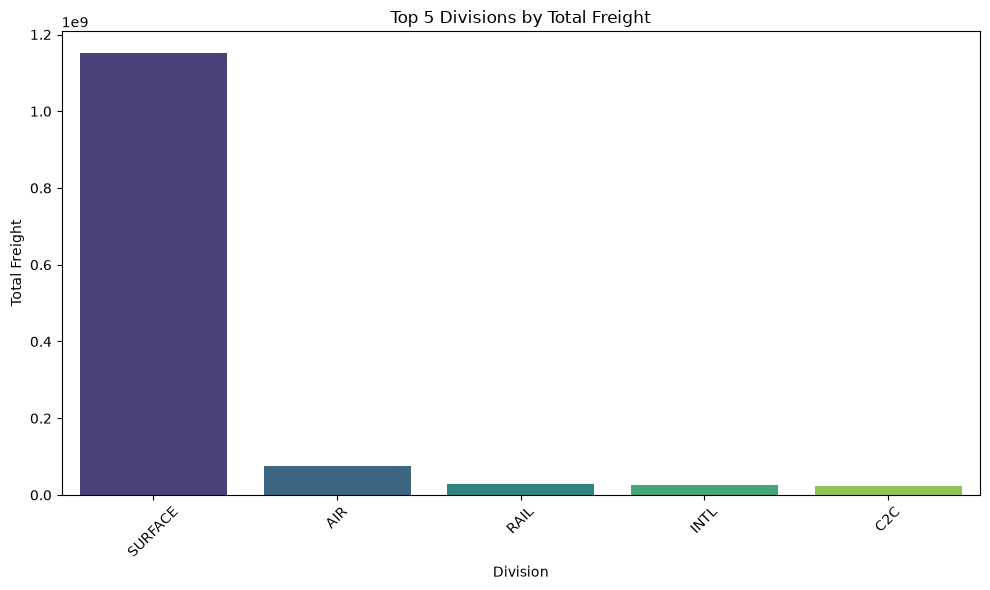

In [11]:
prompt_3 = "Top 5 divisions ka total freight bar chart me dikhao"
engine.ask(prompt_3)

In [2]:
import scipy; print('SciPy:', scipy.__version__)

SciPy: 1.18.1
